In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [6]:
data=pd.read_csv('stores_sales_forecasting.csv', encoding='cp1252')
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [7]:
data=data[['Order Date','Sales']]
data.head()

,Order Date,Sales
0,11/8/2016,261.9600
1,11/8/2016,731.9400
2,10/11/2015,957.5775
3,6/9/2014,48.8600
4,6/9/2014,1706.1840


In [8]:
data.shape

(2121, 2)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order Date  2121 non-null   object 
 1   Sales       2121 non-null   float64
dtypes: float64(1), object(1)
memory usage: 33.3+ KB


In [10]:
data.isnull().sum()

Order Date    0
Sales         0
dtype: int64

In [11]:
data['Order Date'] = pd.to_datetime(data['Order Date'])

In [12]:
data_grouped = data.groupby('Order Date')['Sales'].sum().reset_index()

In [13]:
data_grouped['year'] = data_grouped['Order Date'].dt.year
data_grouped['month'] = data_grouped['Order Date'].dt.month
data_grouped['day'] = data_grouped['Order Date'].dt.day
data_grouped['dayofweek'] = data_grouped['Order Date'].dt.dayofweek
data_grouped.head()

,Order Date,Sales,year,month,day,dayofweek
0,2014-01-06,2573.820,2014,1,6,0
1,2014-01-07,76.728,2014,1,7,1
2,2014-01-10,51.940,2014,1,10,4
3,2014-01-11,9.940,2014,1,11,5
4,2014-01-13,879.939,2014,1,13,0


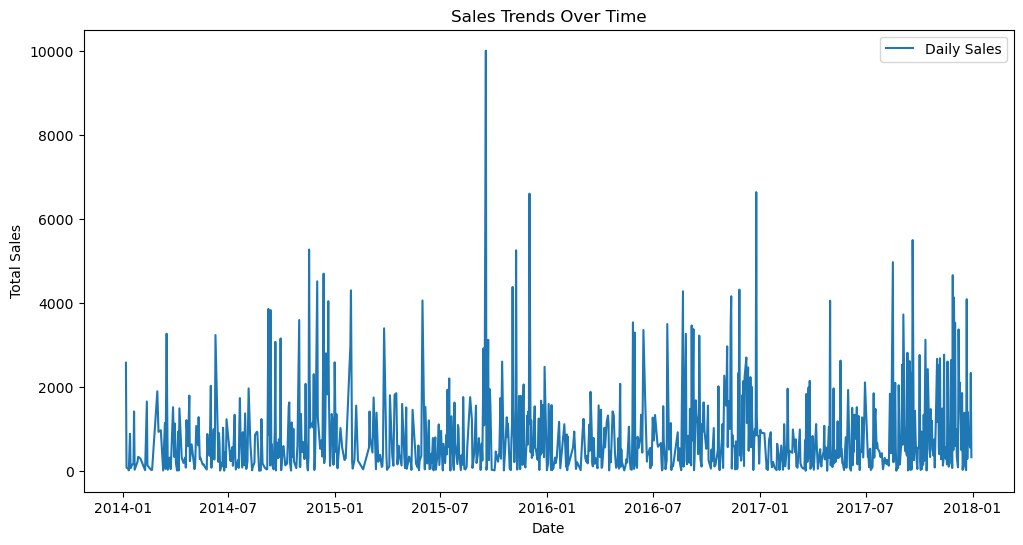

In [14]:
plt.figure(figsize=(12, 6))
plt.plot(data_grouped['Order Date'], data_grouped['Sales'], label='Daily Sales')
plt.title('Sales Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

## Linear Regression

In [16]:
X = data_grouped[['year', 'month', 'day', 'dayofweek']]
y = data_grouped['Sales']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 19.06, 65.02, -0.03,-17.64]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['year','month','day','dayofweek']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.799e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


In [19]:
y_pred = model.predict(X_test)

In [20]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R² Score: {r2:.2f}")

Root Mean Squared Error (RMSE): 1030.95
Mean Absolute Error (MAE): 777.68
R² Score: 0.04


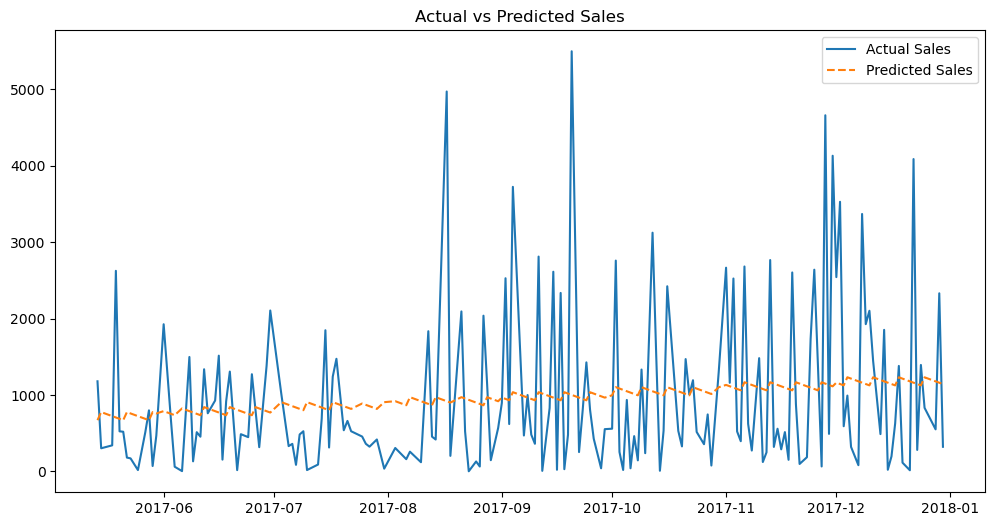

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(data_grouped['Order Date'].iloc[-len(y_test):], y_test, label='Actual Sales')
plt.plot(data_grouped['Order Date'].iloc[-len(y_test):], y_pred, label='Predicted Sales', linestyle='dashed')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.show()

## ARIMA & SARIMA

In [23]:
data_ts = data_grouped[['Order Date', 'Sales']].set_index('Order Date')
data_ts = data_ts.asfreq('D').fillna(0)
test_size = int(len(data_ts)*0.2)
train = data_ts.iloc[:-test_size]
test = data_ts.iloc[-test_size:]

In [33]:
arima_model = SARIMAX(train['Sales'], order=(0, 1, 1)) 
arima_result = arima_model.fit()
arima_forecast = arima_result.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [35]:
sarima_model = SARIMAX(train['Sales'], order=(0, 1, 1), seasonal_order=(0, 0, 2, 7))
sarima_result = sarima_model.fit()
sarima_forecast = sarima_result.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [36]:
arima_rmse = np.sqrt(mean_squared_error(test['Sales'], arima_forecast))
arima_mae = mean_absolute_error(test['Sales'], arima_forecast)
arima_r2 = r2_score(test['Sales'], arima_forecast)

print(f"ARIMA RMSE: {arima_rmse:.2f}")
print(f"ARIMA MAE: {arima_mae:.2f}")
print(f"ARIMA R² Score: {arima_r2:.2f}")

ARIMA RMSE: 1059.68
ARIMA MAE: 614.81
ARIMA R² Score: -0.21


In [39]:
sarima_rmse = np.sqrt(mean_squared_error(test['Sales'], sarima_forecast))
sarima_mae = mean_absolute_error(test['Sales'], sarima_forecast)
sarima_r2 = r2_score(test['Sales'], sarima_forecast)

print(f"SARIMA RMSE: {sarima_rmse:.2f}")
print(f"SARIMA MAE: {sarima_mae:.2f}")
print(f"SARIMA R² Score: {sarima_r2:.2f}")

SARIMA RMSE: 1043.56
SARIMA MAE: 609.45
SARIMA R² Score: -0.18


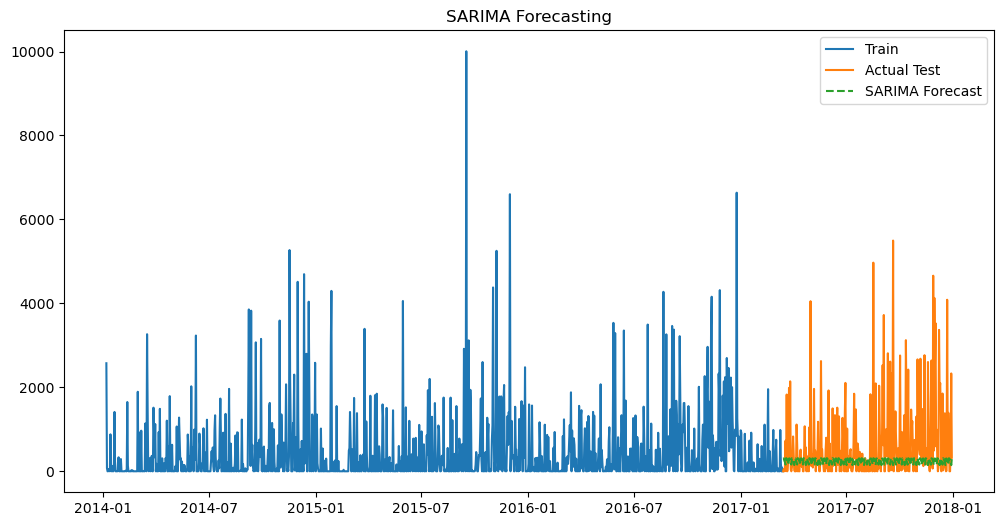

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Actual Test')
plt.plot(test.index, sarima_forecast, label='SARIMA Forecast', linestyle='dashed')
plt.title('SARIMA Forecasting')
plt.legend()
plt.show()

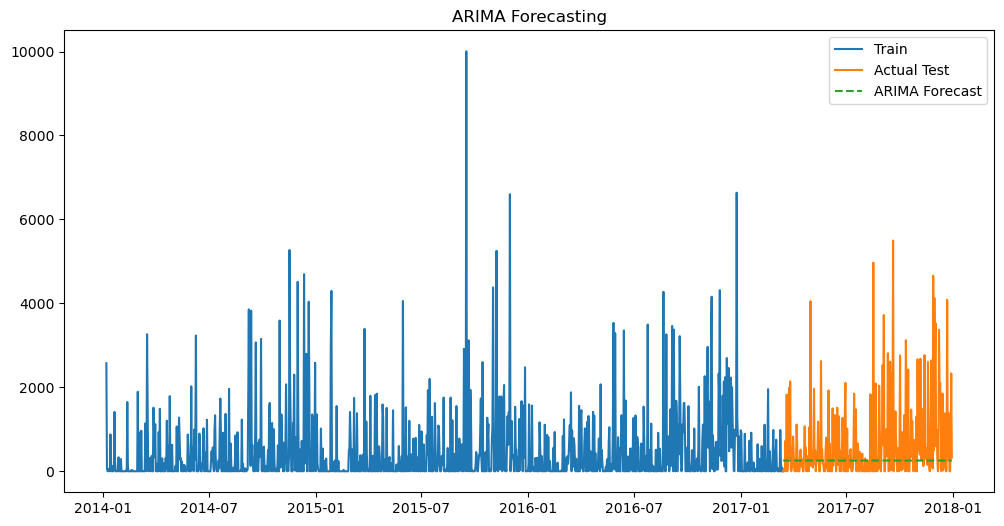

In [29]:
plt.figure(figsize=(12, 6))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Actual Test')
plt.plot(test.index, arima_forecast, label='ARIMA Forecast', linestyle='dashed')
plt.title('ARIMA Forecasting')
plt.legend()
plt.show()

## Prophet

In [58]:
data_prophet = data_grouped[['Order Date', 'Sales']].rename(columns={'Order Date': 'ds', 'Sales': 'y'})
data_prophet['ds'] = pd.to_datetime(data_prophet['ds'])
train_prophet = data_prophet.iloc[:-test_size]
test_prophet = data_prophet.iloc[-test_size:]
model = Prophet(daily_seasonality=True, yearly_seasonality=True)
model.fit(train_prophet)
future = model.make_future_dataframe(periods=test_size, freq='D')
forecast = model.predict(future)
prophet_predictions = forecast.iloc[-test_size:]['yhat']
rmse_prophet = np.sqrt(mean_squared_error(test_prophet['y'], prophet_predictions))
mae_prophet = mean_absolute_error(test_prophet['y'], prophet_predictions)
r2_prophet = r2_score(test_prophet['y'], prophet_predictions)

01:28:23 - cmdstanpy - INFO - Chain [1] start processing
01:28:24 - cmdstanpy - INFO - Chain [1] done processing


In [60]:
print("--- Prophet Evaluation ---")
print(f"RMSE: {rmse_prophet:.2f}")
print(f"MAE: {mae_prophet:.2f}")
print(f"R² Score: {r2_prophet:.2f}")

--- Prophet Evaluation ---
RMSE: 1026.22
MAE: 660.98
R² Score: -0.00


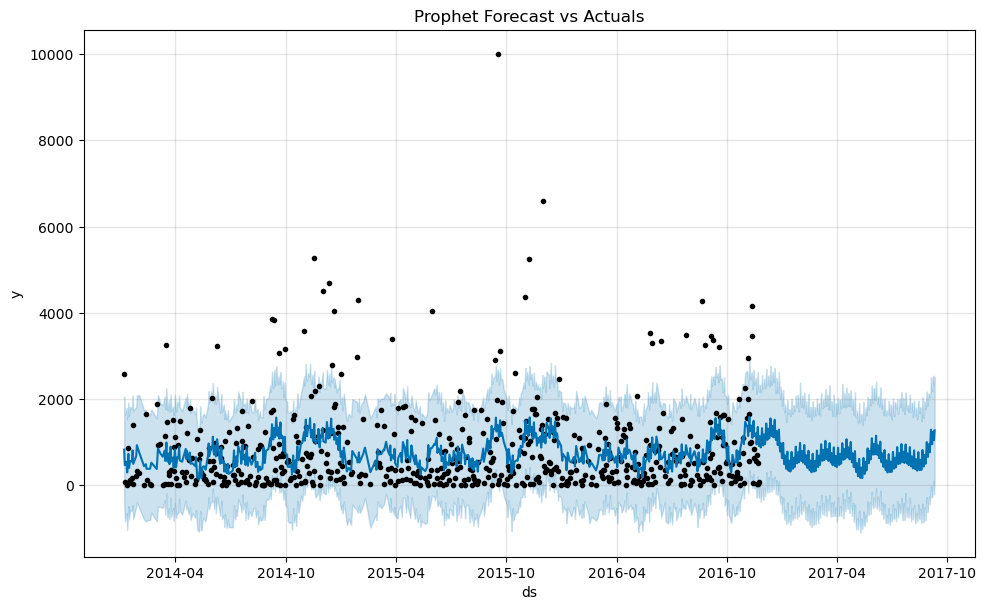

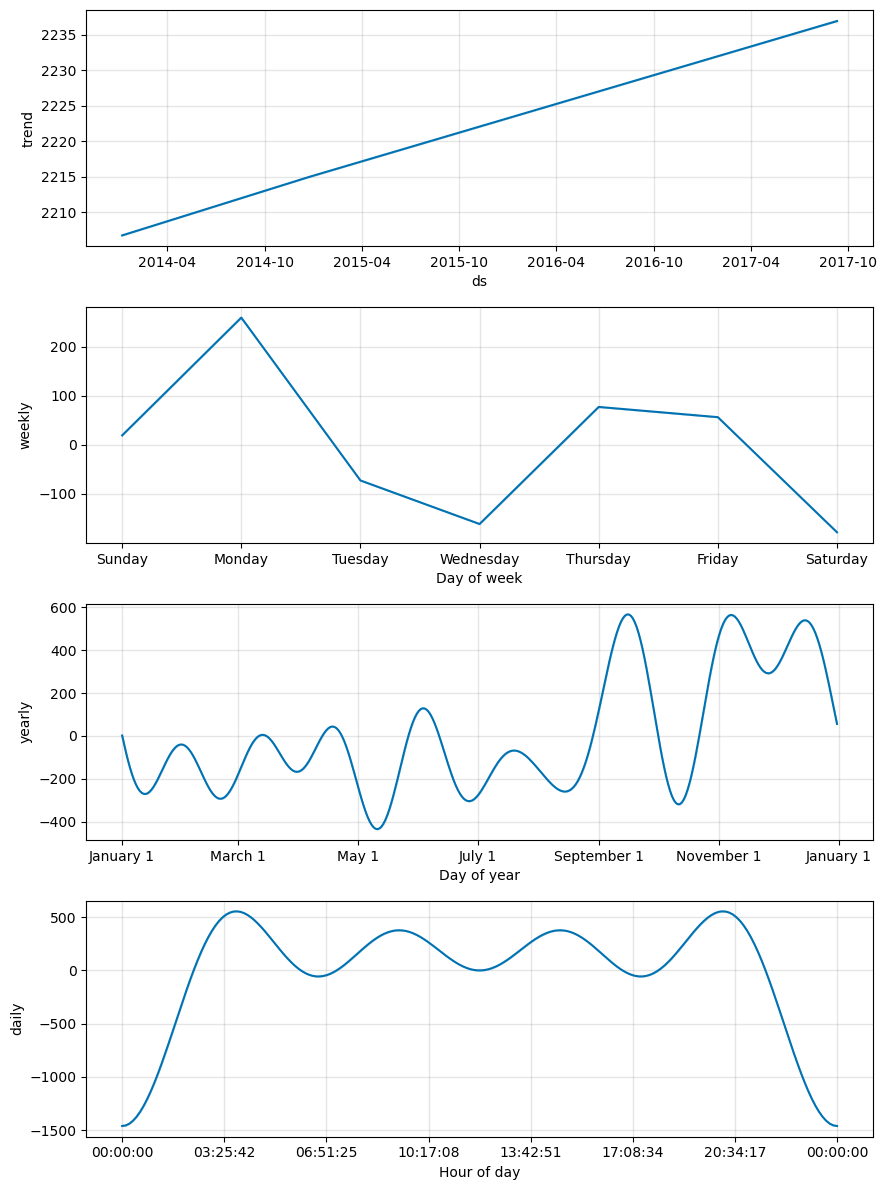

In [62]:
fig1 = model.plot(forecast)
plt.title('Prophet Forecast vs Actuals')
plt.show()
fig2 = model.plot_components(forecast)
plt.show()

### In all model we get MSE is around 1000 and MAE is around 600 for ARIMA & SARIMA, 660 for PROPHET and 773 for Linear Regression, which clearly show Linear Regression has larger error but R^2 value show Linear Regression is best model.

## https://colab.research.google.com/drive/15j55BXCXnjahSlVXjLDbHmcDSmzhXW54?usp=sharing